# Relaciones bivariadas

Cada fila de `mediciones-pronosticos.csv` combina la observación de una estación con el pronóstico
emitido 6 horas antes para ese mismo momento. En este notebook se estudian las relaciones entre pares de variables:

1. Matriz de correlación entre todas las variables numéricas.
2. Observado vs. pronosticado para cada magnitud.
3. Relaciones físicas entre las variables observadas.
4. Ciclo diario (variables vs. hora local).
5. Error de pronóstico vs. hora y probabilidad de precipitación.
6. Dirección vs. velocidad del viento.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm

In [2]:
RAW = '../data/raw/'
PROCESSED = '../data/processed/'
OUT = '../data/out/bivariadas/'

# Misma paleta que en analisis_estaciones.ipynb
AZUL, NARANJA = '#2a78d6', '#eb6834'
GRIS_TEXTO, GRIS_GRILLA = '#52514e', '#e4e3df'

# Secuencial (densidad de puntos) y divergente (correlaciones, centrada en 0)
SECUENCIAL = LinearSegmentedColormap.from_list(
    'azules', ['#cde2fb', '#86b6ef', '#2a78d6', '#184f95', '#0d366b'])
DIVERGENTE = LinearSegmentedColormap.from_list(
    'azul_rojo', ['#184f95', '#6da7ec', '#f0efec', '#ee9190', '#b8302f'])

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GRIS_TEXTO, 'axes.labelcolor': GRIS_TEXTO,
    'xtick.color': GRIS_TEXTO, 'ytick.color': GRIS_TEXTO,
    'axes.grid': True, 'grid.color': GRIS_GRILLA, 'grid.linewidth': 0.6,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.labelsize': 10,
})

figuras = {}  # se exportan todas al final

## 1. Carga y limpieza

In [3]:
mp = pd.read_csv(RAW + 'mediciones-pronosticos.csv')
print(f'{mp.shape[0]:,} filas, {mp.shape[1]} columnas - {mp["station_id"].nunique()} estaciones')
mp.dtypes

294,347 filas, 19 columnas - 474 estaciones


station_id                   str
target_hour_utc              str
horizonte_horas            int64
obs_timestamp                str
fcst_target_timestamp        str
fcst_generated_at            str
obs_temp_c                   str
fcst_temp_c              float64
obs_heat_index_c         float64
obs_rh_pct               float64
fcst_rh_pct              float64
obs_wind_direction_d     float64
obs_windspeed_kmh        float64
fcst_windspeed_kmh       float64
obs_dewpoint_c               str
fcst_dewpoint_c              str
fcst_pop_pct             float64
fecha_particion              str
hora_particion             int64
dtype: object

### Números negativos guardados como texto

`obs_temp_c`, `obs_dewpoint_c` y `fcst_dewpoint_c` se leen como texto porque los valores negativos vienen
precedidos por un apóstrofo (`'-5.56`), un escape típico de exportaciones desde planillas. Se quita el apóstrofo y se convierte a número.

In [4]:
VARIABLES = [
    'obs_temp_c', 'fcst_temp_c', 'obs_dewpoint_c', 'fcst_dewpoint_c',
    'obs_rh_pct', 'fcst_rh_pct', 'obs_windspeed_kmh', 'fcst_windspeed_kmh',
    'obs_heat_index_c', 'obs_wind_direction_d', 'fcst_pop_pct',
]

for c in VARIABLES:
    if not pd.api.types.is_numeric_dtype(mp[c]):
        con_apostrofo = mp[c].str.startswith("'").sum()
        print(f'{c}: {con_apostrofo} valores con apóstrofo')
        mp[c] = pd.to_numeric(mp[c].str.lstrip("'"))

for c in ['obs_timestamp', 'fcst_target_timestamp', 'fcst_generated_at']:
    mp[c] = pd.to_datetime(mp[c], utc=True)

obs_temp_c: 36 valores con apóstrofo


obs_dewpoint_c: 81 valores con apóstrofo


fcst_dewpoint_c: 102 valores con apóstrofo


### Valores inválidos

Las temperaturas bajas (hasta ~1 °C) corresponden a estaciones del norte (MI, WI, MN) y el pronóstico las acompaña,
así que son válidas. Sí hay lecturas imposibles, por ejemplo -42 °C con un pronóstico de 20 °C o un viento de 156 km/h repetido
en varias filas. Se marcan como faltantes:

- temperatura o punto de rocío observados que difieren **más de 15 °C** del pronóstico,
- viento observado **mayor a 120 km/h** (en septiembre no hubo eventos de ese tipo en la región).

In [5]:
invalidos = {
    'obs_temp_c': (mp['obs_temp_c'] - mp['fcst_temp_c']).abs() > 15,
    'obs_dewpoint_c': (mp['obs_dewpoint_c'] - mp['fcst_dewpoint_c']).abs() > 15,
    'obs_windspeed_kmh': mp['obs_windspeed_kmh'] > 120,
}
for c, mascara in invalidos.items():
    print(f'{c}: {mascara.sum()} valores descartados')
    mp.loc[mascara, c] = np.nan

# La sensación térmica depende de la temperatura: si esta se descartó, también aquella
mp.loc[invalidos['obs_temp_c'], 'obs_heat_index_c'] = np.nan

obs_temp_c: 44 valores descartados
obs_dewpoint_c: 43 valores descartados
obs_windspeed_kmh: 6 valores descartados


### Hora local

La hora UTC mezcla el día y la noche entre estaciones de distintos husos. Para estudiar el ciclo diario se convierte
cada observación a la hora local de su estación (`timeZone` de los metadatos).

In [6]:
estaciones = gpd.read_file(PROCESSED + 'estaciones_central.geojson')
mp = mp.merge(estaciones[['id', 'estado', 'timeZone']], left_on='station_id', right_on='id', how='left').drop(columns='id')
print(f"Filas sin zona horaria: {mp['timeZone'].isna().sum()}")

mp['hora_local'] = np.nan
for tz, idx in mp.groupby('timeZone').groups.items():
    mp.loc[idx, 'hora_local'] = mp.loc[idx, 'fcst_target_timestamp'].dt.tz_convert(tz).dt.hour
mp['hora_local'] = mp['hora_local'].astype(int)

mp['timeZone'].value_counts()

Filas sin zona horaria: 0


timeZone
America/Chicago                 270253
America/Detroit                  14280
America/Indiana/Indianapolis      7345
America/Denver                    2469
Name: count, dtype: int64

### Datos faltantes en las observaciones

Los pronósticos están prácticamente completos, pero cerca de un tercio de las filas no tiene observación (hay estaciones
que nunca reportan temperatura, por ejemplo). Cada gráfico usa **todos los pares completos** de las dos variables que compara,
por lo que el `n` cambia de un panel a otro.

In [7]:
(mp[VARIABLES].notna().mean().mul(100).round(1)
 .rename('% de filas con dato').to_frame()
 .sort_values('% de filas con dato'))

,% de filas con dato
obs_heat_index_c,54.2
obs_rh_pct,60.7
obs_dewpoint_c,61.5
obs_wind_direction_d,62.8
obs_windspeed_kmh,63.2
obs_temp_c,63.5
fcst_dewpoint_c,100.0
fcst_temp_c,100.0
fcst_windspeed_kmh,100.0
fcst_rh_pct,100.0


## 2. Matriz de correlación

Se calculan Pearson (relación lineal) y Spearman (relación monótona, robusta a valores extremos).
La dirección del viento se excluye porque es una variable circular (0° y 360° son lo mismo).

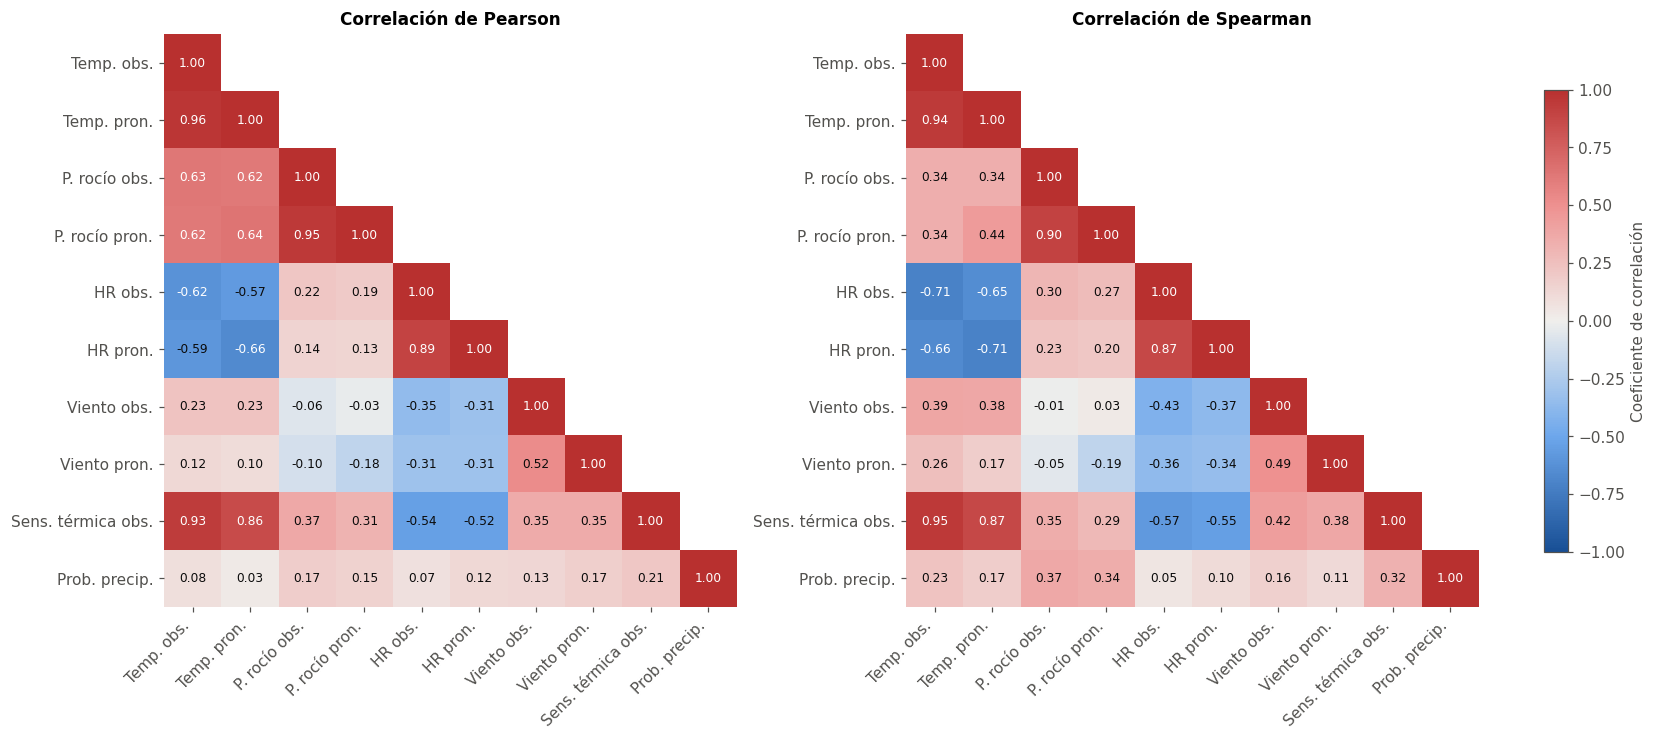

In [8]:
ETIQUETAS = {
    'obs_temp_c': 'Temp. obs.', 'fcst_temp_c': 'Temp. pron.',
    'obs_dewpoint_c': 'P. rocío obs.', 'fcst_dewpoint_c': 'P. rocío pron.',
    'obs_rh_pct': 'HR obs.', 'fcst_rh_pct': 'HR pron.',
    'obs_windspeed_kmh': 'Viento obs.', 'fcst_windspeed_kmh': 'Viento pron.',
    'obs_heat_index_c': 'Sens. térmica obs.', 'fcst_pop_pct': 'Prob. precip.',
}
vars_corr = list(ETIQUETAS)
datos_corr = mp[vars_corr].rename(columns=ETIQUETAS)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), constrained_layout=True)
for ax, metodo, titulo in zip(axes, ['pearson', 'spearman'], ['Pearson', 'Spearman']):
    corr = datos_corr.corr(method=metodo)
    mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
    im = ax.imshow(corr.mask(mascara), cmap=DIVERGENTE, vmin=-1, vmax=1)
    for i in range(len(corr)):
        for j in range(i + 1):
            v = corr.iat[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if abs(v) > 0.6 else '#0b0b0b')
    ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
    ax.set_yticks(range(len(corr)), corr.index)
    ax.grid(False)
    ax.spines[:].set_visible(False)
    ax.set_title(f'Correlación de {titulo}')
fig.colorbar(im, ax=axes, shrink=0.8, label='Coeficiente de correlación')
figuras['01_matriz_correlacion'] = fig
plt.show()

## 3. Observado vs. pronosticado

Cada panel compara la observación con el pronóstico emitido 6 h antes. Con ~190 mil puntos un scatter se satura,
así que se usa un **hexbin** con la cantidad de registros por celda en escala logarítmica. La línea punteada es `y = x`
(pronóstico perfecto).

In [9]:
def hexbin_par(ax, datos, x, y, identidad=False, gridsize=60, texto_abajo=False):
    """Hexbin de densidad para un par de variables, con r de Pearson y rho de Spearman."""
    d = datos[[x, y]].dropna()
    hb = ax.hexbin(d[x], d[y], gridsize=gridsize, bins='log', mincnt=1,
                   cmap=SECUENCIAL, linewidths=0)
    if identidad:
        lims = [d[x].min(), d[x].max()]
        ax.plot(lims, lims, color=NARANJA, lw=1.5, ls='--', label='y = x')
        ax.legend(loc='lower right', frameon=False)
    r = d[x].corr(d[y])
    rho = d[x].corr(d[y], method='spearman')
    ax.text(0.03, 0.03 if texto_abajo else 0.97, f'r = {r:.2f}   ρ = {rho:.2f}\nn = {len(d):,}',
            transform=ax.transAxes, va='bottom' if texto_abajo else 'top', fontsize=9, color=GRIS_TEXTO,
            bbox=dict(fc='white', ec='none', alpha=0.85))
    ax.grid(False)
    return hb


def escala_comun(hexbins):
    """Misma escala de color en todos los paneles, para que la barra de color valga para todos."""
    vmax = max(hb.get_array().max() for hb in hexbins)
    for hb in hexbins:
        hb.set_norm(LogNorm(vmin=1, vmax=vmax))
    return hexbins[-1]

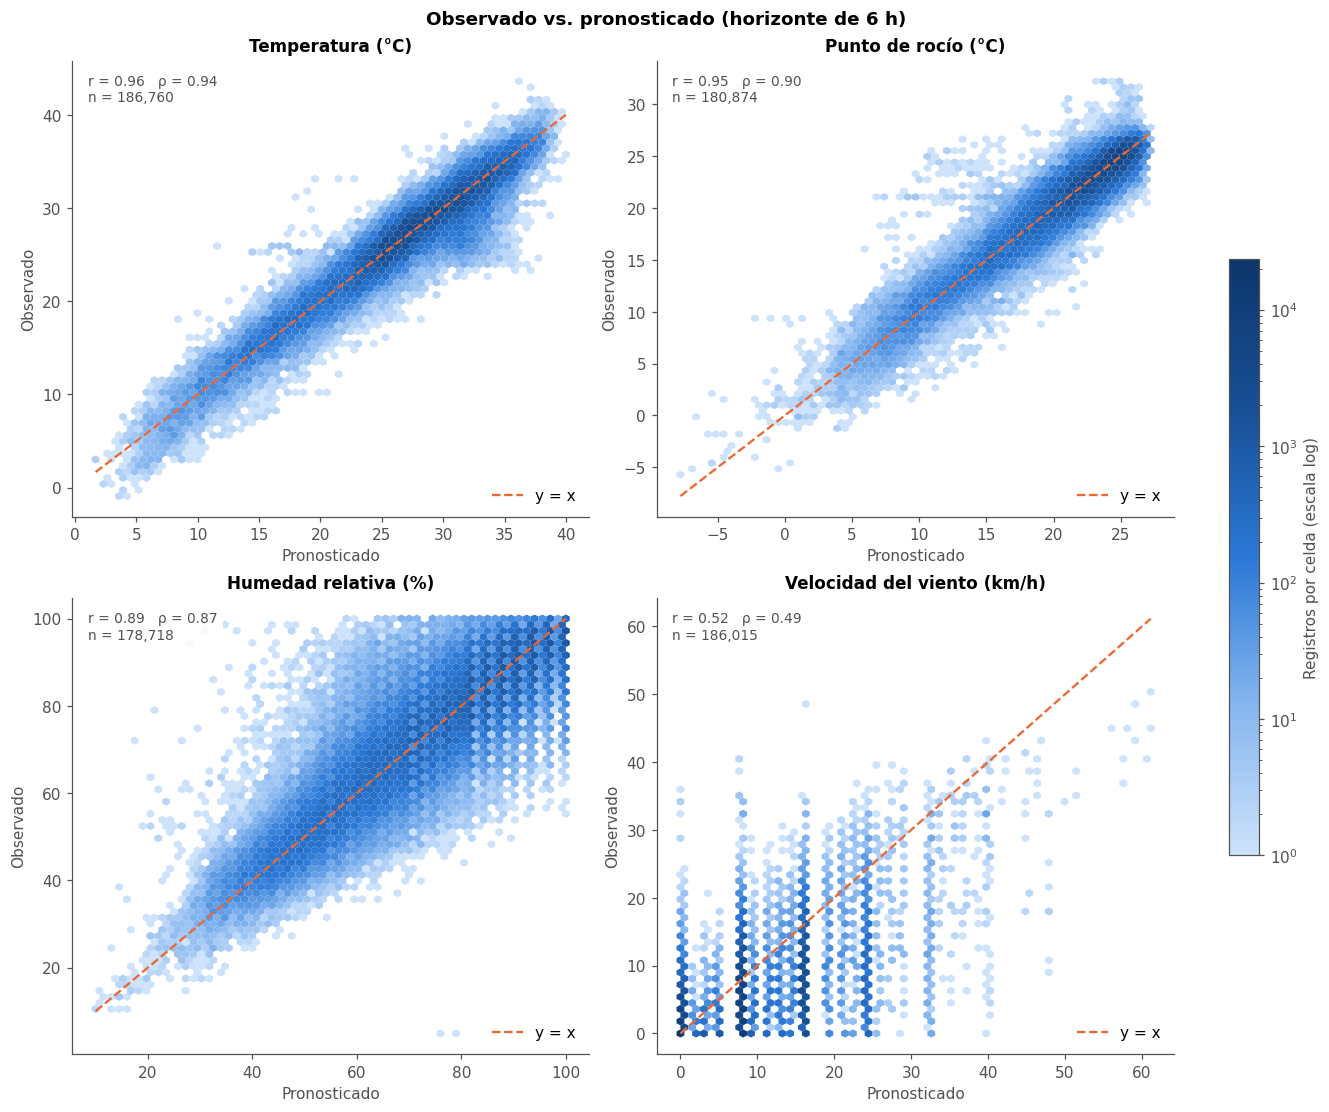

In [10]:
PARES_OBS_PRON = [
    ('Temperatura (°C)', 'fcst_temp_c', 'obs_temp_c'),
    ('Punto de rocío (°C)', 'fcst_dewpoint_c', 'obs_dewpoint_c'),
    ('Humedad relativa (%)', 'fcst_rh_pct', 'obs_rh_pct'),
    ('Velocidad del viento (km/h)', 'fcst_windspeed_kmh', 'obs_windspeed_kmh'),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
hexbins = []
for ax, (nombre, pron, obs) in zip(axes.flat, PARES_OBS_PRON):
    hexbins.append(hexbin_par(ax, mp, pron, obs, identidad=True))
    ax.set(title=nombre, xlabel='Pronosticado', ylabel='Observado')
fig.colorbar(escala_comun(hexbins), ax=axes, shrink=0.6, label='Registros por celda (escala log)')
fig.suptitle('Observado vs. pronosticado (horizonte de 6 h)', fontweight='bold')
figuras['02_observado_vs_pronosticado'] = fig
plt.show()

Resumen numérico del acuerdo entre observación y pronóstico (error = observado − pronosticado):

In [11]:
filas = []
for nombre, pron, obs in PARES_OBS_PRON:
    d = mp[[pron, obs]].dropna()
    error = d[obs] - d[pron]
    filas.append({
        'Variable': nombre, 'n': len(d),
        'Pearson r': d[obs].corr(d[pron]),
        'Sesgo (media del error)': error.mean(),
        'MAE': error.abs().mean(),
        'RMSE': np.sqrt((error ** 2).mean()),
    })
tabla_obs_pron = pd.DataFrame(filas).set_index('Variable').round(2)
tabla_obs_pron

,n,Pearson r,Sesgo (media del error),MAE,RMSE
Variable,,,,,
Temperatura (°C),186760,0.96,-0.07,1.08,1.48
Punto de rocío (°C),180874,0.95,0.01,0.93,1.29
Humedad relativa (%),178718,0.89,0.23,5.71,7.66
Velocidad del viento (km/h),186015,0.52,-2.93,4.80,6.48


## 4. Relaciones entre variables observadas

Relaciones físicas esperables entre las mediciones:

- **Temperatura vs. humedad relativa**: con la misma cantidad de vapor, el aire más caliente tiene menor HR.
- **Temperatura vs. punto de rocío**: el punto de rocío nunca supera a la temperatura (cota superior `y = x`).
- **Temperatura vs. sensación térmica**: coinciden con calor seco y se separan cuando la humedad es alta.
- **Humedad relativa vs. viento**: el viento mezcla el aire y suele coincidir con horas de menor HR.

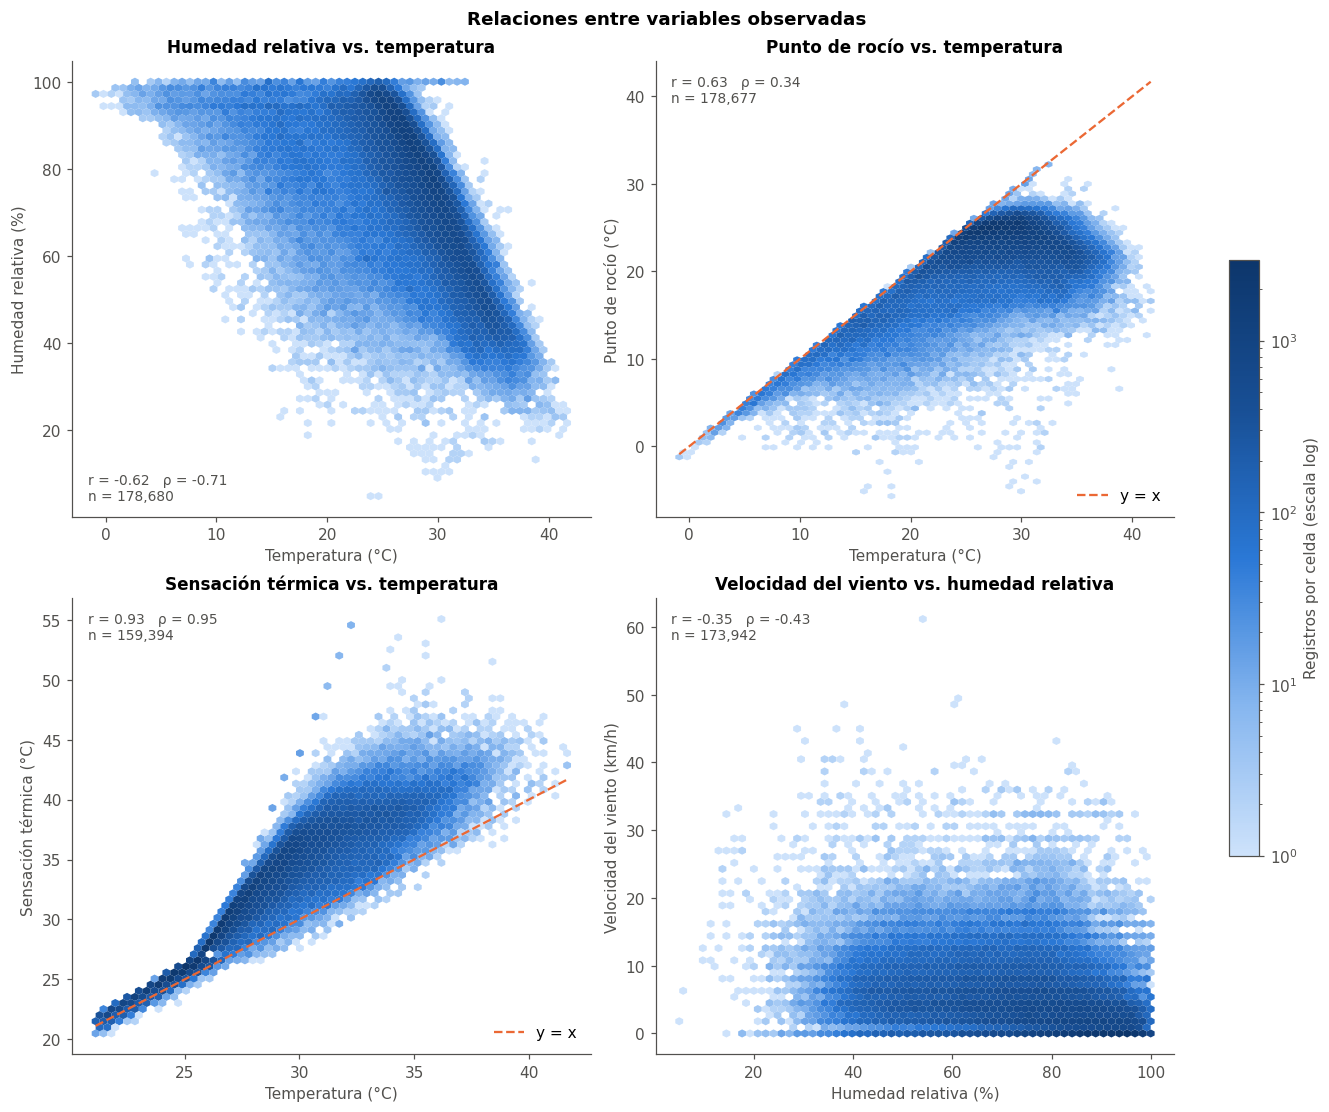

In [12]:
PARES_OBS = [
    ('obs_temp_c', 'obs_rh_pct', 'Temperatura (°C)', 'Humedad relativa (%)', False, True),
    ('obs_temp_c', 'obs_dewpoint_c', 'Temperatura (°C)', 'Punto de rocío (°C)', True, False),
    ('obs_temp_c', 'obs_heat_index_c', 'Temperatura (°C)', 'Sensación térmica (°C)', True, False),
    ('obs_rh_pct', 'obs_windspeed_kmh', 'Humedad relativa (%)', 'Velocidad del viento (km/h)', False, False),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
hexbins = []
for ax, (x, y, etiqueta_x, etiqueta_y, identidad, texto_abajo) in zip(axes.flat, PARES_OBS):
    hexbins.append(hexbin_par(ax, mp, x, y, identidad=identidad, texto_abajo=texto_abajo))
    ax.set(title=f'{etiqueta_y.split(" (")[0]} vs. {etiqueta_x.split(" (")[0].lower()}',
           xlabel=etiqueta_x, ylabel=etiqueta_y)
fig.colorbar(escala_comun(hexbins), ax=axes, shrink=0.6, label='Registros por celda (escala log)')
fig.suptitle('Relaciones entre variables observadas', fontweight='bold')
figuras['03_relaciones_observadas'] = fig
plt.show()

## 5. Ciclo diario

Cada variable se grafica contra la hora local. La línea es la media y la banda el rango intercuartílico (P25–P75)
de todas las estaciones y días. Se usa la media y no la mediana porque el pronóstico de viento toma pocos valores
(8,05 km/h = 5 mph, 16,09 km/h = 10 mph, ...) y su mediana salta de un escalón a otro. Se usa un panel por variable para no mezclar escalas en un mismo eje.

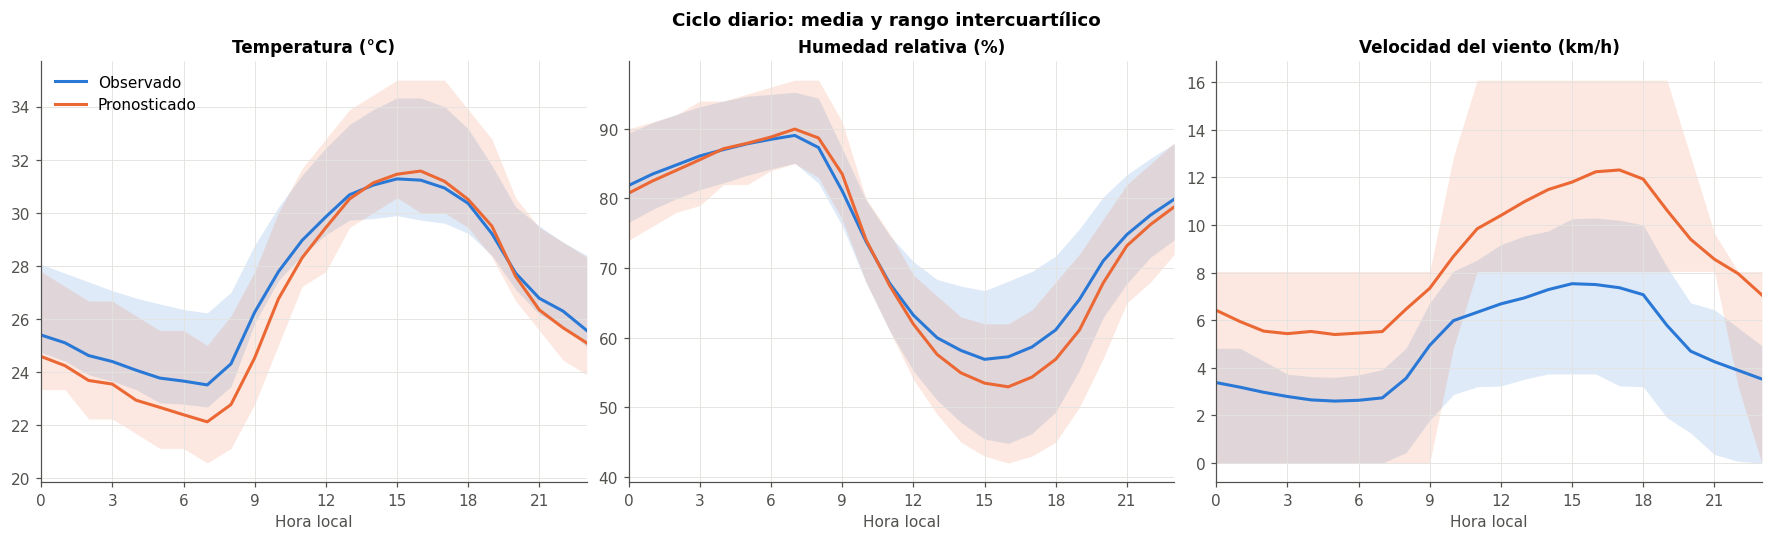

In [13]:
def banda_por_hora(ax, datos, variable, color, etiqueta):
    """Media y rango intercuartílico de una variable por hora local."""
    g = datos.groupby('hora_local')[variable]
    q = g.quantile([0.25, 0.75]).unstack()
    ax.fill_between(q.index, q[0.25], q[0.75], color=color, alpha=0.15, linewidth=0)
    ax.plot(q.index, g.mean(), color=color, lw=2, label=etiqueta)

CICLO = [
    ('Temperatura (°C)', 'obs_temp_c', 'fcst_temp_c'),
    ('Humedad relativa (%)', 'obs_rh_pct', 'fcst_rh_pct'),
    ('Velocidad del viento (km/h)', 'obs_windspeed_kmh', 'fcst_windspeed_kmh'),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
for ax, (nombre, obs, pron) in zip(axes, CICLO):
    banda_por_hora(ax, mp, obs, AZUL, 'Observado')
    banda_por_hora(ax, mp, pron, NARANJA, 'Pronosticado')
    ax.set(title=nombre, xlabel='Hora local', xticks=range(0, 24, 3), xlim=(0, 23))
axes[0].legend(frameon=False)
fig.suptitle('Ciclo diario: media y rango intercuartílico', fontweight='bold')
figuras['04_ciclo_diario'] = fig
plt.show()

## 6. Error del pronóstico de temperatura

Se analiza el error `observado − pronosticado` de la temperatura frente a dos variables:

- la **hora local**, para ver si el modelo falla sistemáticamente en algún momento del día;
- la **probabilidad de precipitación** pronosticada, ya que la lluvia y la nubosidad son difíciles de anticipar
  y enfrían el aire.

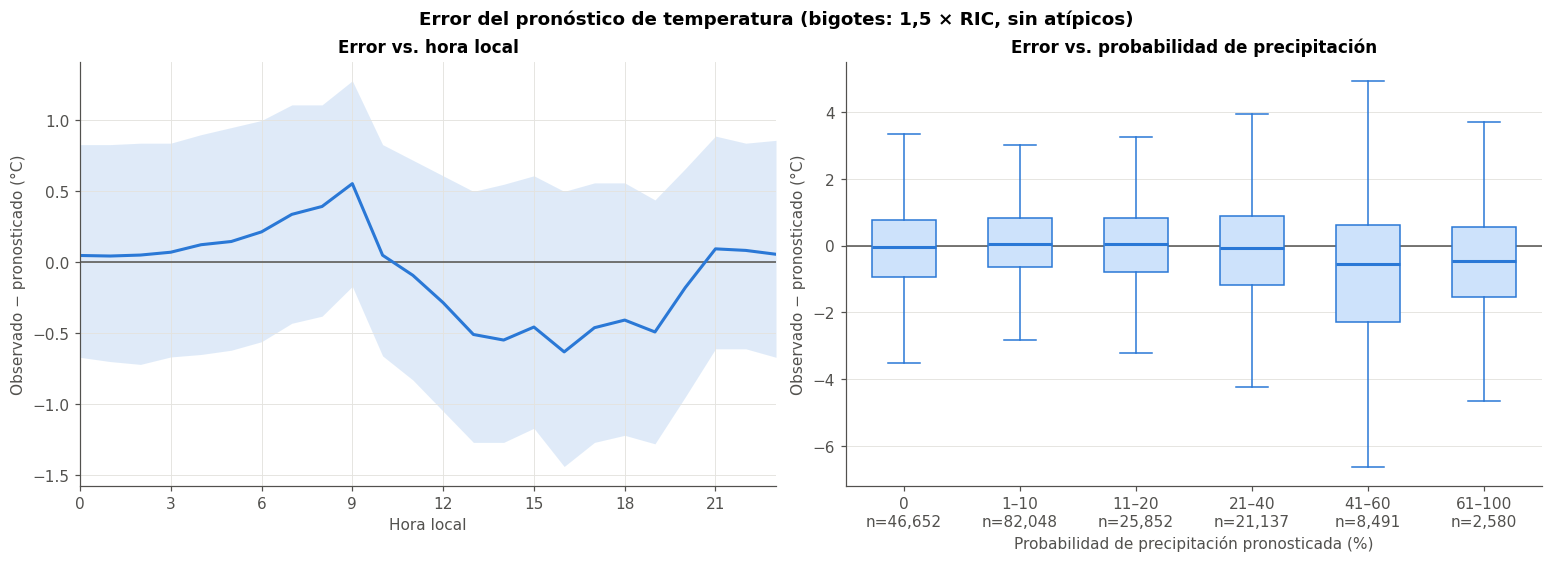

In [14]:
mp['error_temp_c'] = mp['obs_temp_c'] - mp['fcst_temp_c']

cortes_pop = [-0.1, 0, 10, 20, 40, 60, 100]
etiquetas_pop = ['0', '1–10', '11–20', '21–40', '41–60', '61–100']
mp['pop_rango'] = pd.cut(mp['fcst_pop_pct'], cortes_pop, labels=etiquetas_pop)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

ax1.axhline(0, color=GRIS_TEXTO, lw=1)
banda_por_hora(ax1, mp, 'error_temp_c', AZUL, 'Media')
ax1.set(title='Error vs. hora local', xlabel='Hora local', ylabel='Observado − pronosticado (°C)',
        xticks=range(0, 24, 3), xlim=(0, 23))

d = mp.dropna(subset=['error_temp_c'])
grupos = [g['error_temp_c'].values for _, g in d.groupby('pop_rango', observed=False)]
ax2.axhline(0, color=GRIS_TEXTO, lw=1)
etiquetas_n = [f'{e}\nn={len(g):,}' for e, g in zip(etiquetas_pop, grupos)]
ax2.boxplot(grupos, tick_labels=etiquetas_n, showfliers=False, widths=0.55, patch_artist=True,
            boxprops=dict(facecolor='#cde2fb', edgecolor=AZUL), medianprops=dict(color=AZUL, lw=2),
            whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL))
ax2.set(title='Error vs. probabilidad de precipitación', xlabel='Probabilidad de precipitación pronosticada (%)',
        ylabel='Observado − pronosticado (°C)')
ax2.grid(axis='x', visible=False)

fig.suptitle('Error del pronóstico de temperatura (bigotes: 1,5 × RIC, sin atípicos)', fontweight='bold')
figuras['05_error_temperatura'] = fig
plt.show()

In [15]:
(mp.groupby('pop_rango', observed=False)['error_temp_c']
 .agg(n='count', sesgo='mean', mediana='median', MAE=lambda e: e.abs().mean())
 .round(2))

,n,sesgo,mediana,MAE
pop_rango,,,,
0,46652,-0.09,-0.05,1.06
1–10,82048,0.09,0.06,0.94
11–20,25852,-0.05,0.05,1.07
21–40,21137,-0.28,-0.06,1.36
41–60,8491,-0.96,-0.56,1.86
61–100,2580,-0.53,-0.45,1.37


## 7. Dirección vs. velocidad del viento

Rosa de los vientos: cada barra es un sector de 22,5° según la dirección **desde la que sopla** el viento (0° = norte),
su largo es el porcentaje de observaciones en ese sector y los tramos apilados indican la velocidad (más oscuro = más rápido).
Se excluyen las calmas (velocidad 0), que se reportan con dirección 0°.

Calmas excluidas: 34,417 (18.6% de las observaciones de viento)


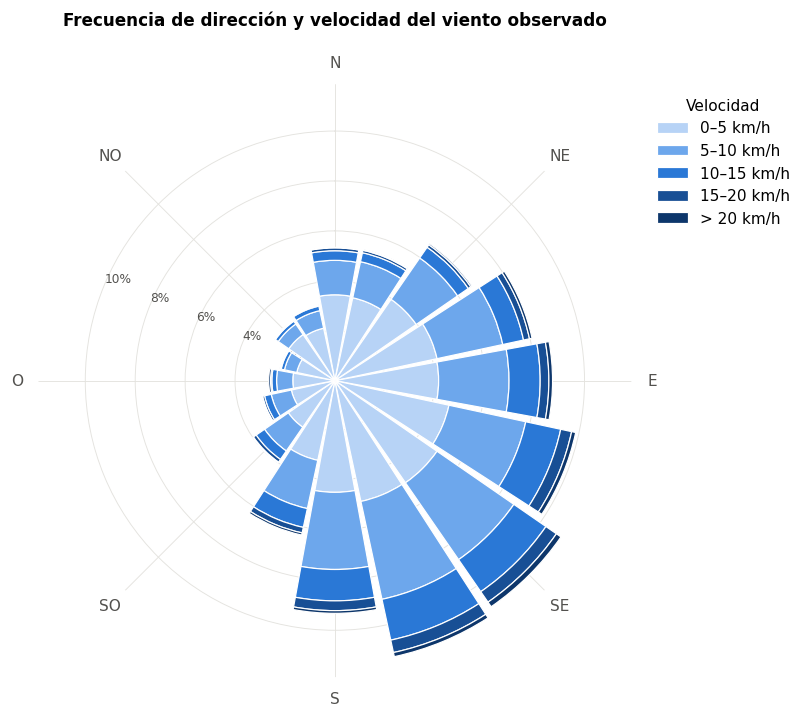

In [16]:
viento = mp[['obs_wind_direction_d', 'obs_windspeed_kmh']].dropna()
calmas = viento['obs_windspeed_kmh'].eq(0)
print(f'Calmas excluidas: {calmas.sum():,} ({calmas.mean():.1%} de las observaciones de viento)')
viento = viento[~calmas]

SECTOR = 22.5
cortes_vel = [0, 5, 10, 15, 20, np.inf]
etiquetas_vel = ['0–5', '5–10', '10–15', '15–20', '> 20']
colores_vel = ['#b7d3f6', '#6da7ec', '#2a78d6', '#184f95', '#0d366b']

sector = ((viento['obs_wind_direction_d'] + SECTOR / 2) % 360 // SECTOR).astype(int)
rango_vel = pd.cut(viento['obs_windspeed_kmh'], cortes_vel, labels=etiquetas_vel)
frecuencia = (pd.crosstab(sector, rango_vel, normalize=True) * 100).reindex(range(16), fill_value=0)

angulos = np.deg2rad(frecuencia.index * SECTOR)
fig = plt.figure(figsize=(7.5, 7))
ax = fig.add_subplot(projection='polar')
ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)
base = np.zeros(len(frecuencia))
for etiqueta, color in zip(etiquetas_vel, colores_vel):
    ax.bar(angulos, frecuencia[etiqueta], width=np.deg2rad(SECTOR) * 0.92, bottom=base,
           color=color, edgecolor='white', linewidth=0.8, label=f'{etiqueta} km/h')
    base += frecuencia[etiqueta].values
ax.set_xticks(np.deg2rad(range(0, 360, 45)), ['N', 'NE', 'E', 'SE', 'S', 'SO', 'O', 'NO'])
ax.set_rlabel_position(292.5)  # sector con poco viento, las etiquetas no quedan tapadas
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
ax.tick_params(axis='y', labelsize=8, colors=GRIS_TEXTO)
ax.grid(color=GRIS_GRILLA)
ax.set_axisbelow(True)
ax.spines['polar'].set_visible(False)
ax.legend(title='Velocidad', loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
ax.set_title('Frecuencia de dirección y velocidad del viento observado', pad=20)
figuras['06_direccion_velocidad_viento'] = fig
plt.show()

In [17]:
sectores = ['N', 'NE', 'E', 'SE', 'S', 'SO', 'O', 'NO']
viento['sector'] = pd.Categorical(
    np.array(sectores)[(((viento['obs_wind_direction_d'] + 22.5) % 360) // 45).astype(int)], sectores)
(viento.groupby('sector', observed=False)['obs_windspeed_kmh']
 .agg(frecuencia_pct=lambda s: 100 * len(s) / len(viento), mediana_kmh='median', p90_kmh=lambda s: s.quantile(0.9))
 .round(1))

,frecuencia_pct,mediana_kmh,p90_kmh
sector,,,
N,9.5,3.7,9.8
NE,13.5,4.4,10.5
E,17.4,5.3,12.9
SE,22.2,5.6,13.2
S,18.2,5.3,12.9
SO,8.4,4.8,11.7
O,5.2,3.8,10.8
NO,5.6,3.2,8.7


## 8. Conclusiones

**Calidad de los datos**

- Los negativos de tres columnas venían como texto (`'-5.56`) y hubo que convertirlos. Además se descartaron 44 temperaturas,
  43 puntos de rocío y 6 vientos físicamente imposibles.
- Cerca del 37 % de las filas no tiene observación. Los pronósticos, en cambio, están completos. Cada gráfico usa los pares disponibles.

**Observado vs. pronosticado (6 h)**

- Temperatura (r = 0,96; MAE ≈ 1,1 °C) y punto de rocío (r = 0,95; MAE ≈ 0,9 °C) se pronostican muy bien y casi sin sesgo.
- La humedad relativa también acompaña bien (r = 0,89; MAE ≈ 5,7 puntos). Se nota la saturación en 100 %.
- El viento es la variable peor pronosticada (r = 0,52). El pronóstico **sobreestima** la velocidad en ≈ 2,9 km/h en promedio,
  sobre todo de noche, cuando muchas estaciones reportan calma (18,6 % de las observaciones de viento). Además, el pronóstico está
  cuantizado en millas por hora (5 mph = 8,05 km/h), lo que genera las franjas verticales.

**Relaciones entre variables**

- Temperatura y humedad relativa tienen una relación negativa fuerte (ρ = −0,71): a mayor temperatura, menor HR. Es el ciclo diario
  el que las mueve en direcciones opuestas.
- El punto de rocío queda siempre por debajo de la temperatura (cota `y = x`). Sube con ella hasta ≈ 25 °C y luego se estabiliza,
  por eso Spearman (0,34) es mucho menor que Pearson (0,63).
- La sensación térmica coincide con la temperatura por debajo de ≈ 26 °C y se separa hacia arriba con calor húmedo
  (hasta 10–15 °C más). En el dataset sólo aparece a partir de ≈ 21 °C.
- El viento se asocia débilmente con menor humedad (ρ = −0,43) y mayor temperatura (ρ = 0,39): sopla más fuerte por la tarde.
- La probabilidad de precipitación se relaciona sobre todo con la humedad del aire (ρ = 0,37 con el punto de rocío).

**Error del pronóstico de temperatura**

- Tiene un patrón diario: a primera hora de la mañana el pronóstico es algo más frío que lo observado (+0,5 °C a las 9 h),
  y por la tarde algo más cálido (−0,5 °C entre las 13 y las 19 h).
- Con probabilidad de precipitación intermedia (41–60 %) el error aumenta (MAE 1,86 °C) y el pronóstico sobreestima la temperatura
  (sesgo −0,96 °C). Cuando la lluvia es incierta, el enfriamiento que produce es difícil de anticipar.

**Viento**

- Predominan los vientos del **sureste, sur y este** (≈ 58 % de las observaciones sin calma), que son también los más intensos
  (P90 ≈ 13 km/h). Es coherente con el flujo de aire húmedo desde el Golfo de México. Los del norte y el noroeste son menos
  frecuentes y más débiles.

## 9. Exportación de los gráficos

In [18]:
import os

os.makedirs(OUT, exist_ok=True)
for nombre, fig in figuras.items():
    fig.savefig(OUT + f'{nombre}.png', dpi=300, bbox_inches='tight', facecolor='white')
tabla_obs_pron.to_csv(OUT + 'tabla_observado_vs_pronosticado.csv')
print(f'Guardados {len(figuras)} gráficos y 1 tabla en {OUT}')

Guardados 6 gráficos y 1 tabla en ../data/out/bivariadas/
